In [1]:
import kagglehub
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [2]:
path = kagglehub.dataset_download("rohitgrewal/loan-approval-dataset")

print("Path to dataset files:", path)

100%|██████████| 80.6k/80.6k [00:00<00:00, 46.5MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/rohitgrewal/loan-approval-dataset/versions/1


In [3]:
file_path = os.path.join(path, "loan_approval_dataset.csv")

df = pd.read_csv(file_path)

df.columns = df.columns.str.strip()

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Shape: (4269, 13)


,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


In [4]:
print(df.info())
print(df.describe())
print(df.isnull().sum())
print(df["loan_status"].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   loan_id                   4269 non-null   int64 
 1   no_of_dependents          4269 non-null   int64 
 2   education                 4269 non-null   object
 3   self_employed             4269 non-null   object
 4   income_annum              4269 non-null   int64 
 5   loan_amount               4269 non-null   int64 
 6   loan_term                 4269 non-null   int64 
 7   cibil_score               4269 non-null   int64 
 8   residential_assets_value  4269 non-null   int64 
 9   commercial_assets_value   4269 non-null   int64 
 10  luxury_assets_value       4269 non-null   int64 
 11  bank_asset_value          4269 non-null   int64 
 12  loan_status               4269 non-null   object
dtypes: int64(10), object(3)
memory usage: 433.7+ KB
None
           loan_id  no_of

In [5]:
df = df.drop(
    columns=[col for col in ["id", "loan_id"] if col in df.columns]
)

display(df.head())

,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


In [6]:
df.columns = df.columns.str.strip()

for column in df.select_dtypes(include="object").columns:
    df[column] = df[column].astype(str).str.strip()

df["loan_status"] = df["loan_status"].str.lower().map({
    "approved": 1,
    "rejected": 0
})

df = df.dropna(subset=["loan_status"])
df["loan_status"] = df["loan_status"].astype(int)

label_encoders = {}

for column in df.select_dtypes(include="object").columns:
    le = LabelEncoder()
    df[column] = le.fit_transform(df[column])
    label_encoders[column] = le

display(df.head())

,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,2,0,0,9600000,29900000,12,778,2400000,17600000,22700000,8000000,1
1,0,1,1,4100000,12200000,8,417,2700000,2200000,8800000,3300000,0
2,3,0,0,9100000,29700000,20,506,7100000,4500000,33300000,12800000,0
3,3,0,0,8200000,30700000,8,467,18200000,3300000,23300000,7900000,0
4,5,1,1,9800000,24200000,20,382,12400000,8200000,29400000,5000000,0


In [7]:
X = df.drop("loan_status", axis=1)
y = df["loan_status"]

X = X.fillna(X.median())

print("X shape:", X.shape)
print("y shape:", y.shape)

display(X.head())

X shape: (4269, 11)
y shape: (4269,)


,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
0,2,0,0,9600000,29900000,12,778,2400000,17600000,22700000,8000000
1,0,1,1,4100000,12200000,8,417,2700000,2200000,8800000,3300000
2,3,0,0,9100000,29700000,20,506,7100000,4500000,33300000,12800000
3,3,0,0,8200000,30700000,8,467,18200000,3300000,23300000,7900000
4,5,1,1,9800000,24200000,20,382,12400000,8200000,29400000,5000000


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (3415, 11)
X_test: (854, 11)
y_train: (3415,)
y_test: (854,)


In [9]:
id3_model = DecisionTreeClassifier(
    criterion="entropy",
    random_state=42
)

id3_model.fit(X_train, y_train)

DecisionTreeClassifier(criterion='entropy', random_state=42)

In [10]:
y_pred_id3 = id3_model.predict(X_test)

In [11]:
print("ID3 DECISION TREE")
print("----------------------")

print("Accuracy :", accuracy_score(y_test, y_pred_id3))
print("Precision:", precision_score(y_test, y_pred_id3, zero_division=0))
print("Recall   :", recall_score(y_test, y_pred_id3, zero_division=0))
print("F1 Score :", f1_score(y_test, y_pred_id3, zero_division=0))

ID3 DECISION TREE
----------------------
Accuracy : 0.9824355971896955
Precision: 0.9813432835820896
Recall   : 0.9905838041431262
F1 Score : 0.985941893158388


In [12]:
nb_model = GaussianNB()

nb_model.fit(X_train, y_train)

GaussianNB()

In [13]:
y_pred_nb = nb_model.predict(X_test)

In [14]:
print("NAIVE BAYES")
print("----------------------")

print("Accuracy :", accuracy_score(y_test, y_pred_nb))
print("Precision:", precision_score(y_test, y_pred_nb, zero_division=0))
print("Recall   :", recall_score(y_test, y_pred_nb, zero_division=0))
print("F1 Score :", f1_score(y_test, y_pred_nb, zero_division=0))

NAIVE BAYES
----------------------
Accuracy : 0.752927400468384
Precision: 0.721606648199446
Recall   : 0.9811676082862524
F1 Score : 0.8316041500399042


In [15]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training and testing data scaled successfully")

Training and testing data scaled successfully


In [16]:
knn_model = KNeighborsClassifier(n_neighbors=10)

knn_model.fit(X_train_scaled, y_train)

y_pred_knn = knn_model.predict(X_test_scaled)

In [17]:
print("KNN CLASSIFIER")
print("----------------------")

print("Accuracy :", accuracy_score(y_test, y_pred_knn))
print("Precision:", precision_score(y_test, y_pred_knn, zero_division=0))
print("Recall   :", recall_score(y_test, y_pred_knn, zero_division=0))
print("F1 Score :", f1_score(y_test, y_pred_knn, zero_division=0))

KNN CLASSIFIER
----------------------
Accuracy : 0.9016393442622951
Precision: 0.9339805825242719
Recall   : 0.9058380414312618
F1 Score : 0.9196940726577438


In [18]:
svm_model = SVC(kernel="linear", random_state=42)

svm_model.fit(X_train_scaled, y_train)

SVC(kernel='linear', random_state=42)

In [19]:
y_pred_svm = svm_model.predict(X_test_scaled)

In [20]:
print("SUPPORT VECTOR MACHINE")
print("----------------------")

print("Accuracy :", accuracy_score(y_test, y_pred_svm))
print("Precision:", precision_score(y_test, y_pred_svm, zero_division=0))
print("Recall   :", recall_score(y_test, y_pred_svm, zero_division=0))
print("F1 Score :", f1_score(y_test, y_pred_svm, zero_division=0))

SUPPORT VECTOR MACHINE
----------------------
Accuracy : 0.9227166276346604
Precision: 0.9345794392523364
Recall   : 0.9416195856873822
F1 Score : 0.9380863039399625


In [21]:
models_predictions = {
    "ID3 Decision Tree": y_pred_id3,
    "Naive Bayes": y_pred_nb,
    "KNN": y_pred_knn,
    "SVM": y_pred_svm
}

results = []

for name, predictions in models_predictions.items():
    results.append({
        "Algorithm": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1 Score": f1_score(y_test, predictions, zero_division=0)
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Algorithm,Accuracy,Precision,Recall,F1 Score
0,ID3 Decision Tree,0.9824,0.9813,0.9906,0.9859
1,Naive Bayes,0.7529,0.7216,0.9812,0.8316
2,KNN,0.9016,0.9340,0.9058,0.9197
3,SVM,0.9227,0.9346,0.9416,0.9381


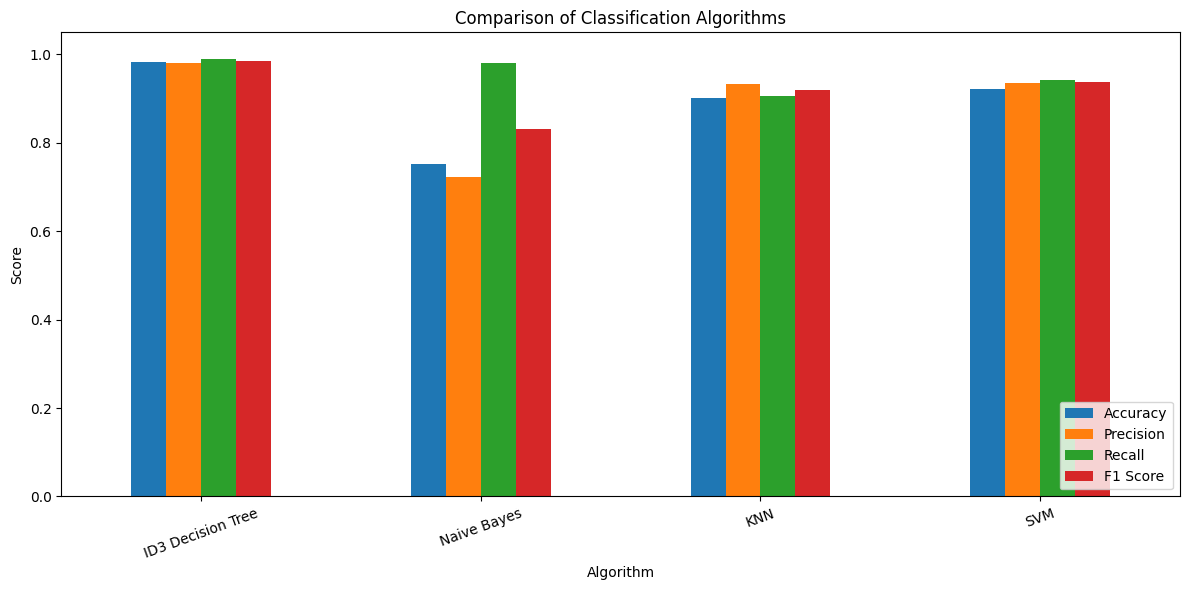

In [22]:
results_df.set_index("Algorithm")[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
].plot(kind="bar", figsize=(12, 6))

plt.title("Comparison of Classification Algorithms")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=20)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

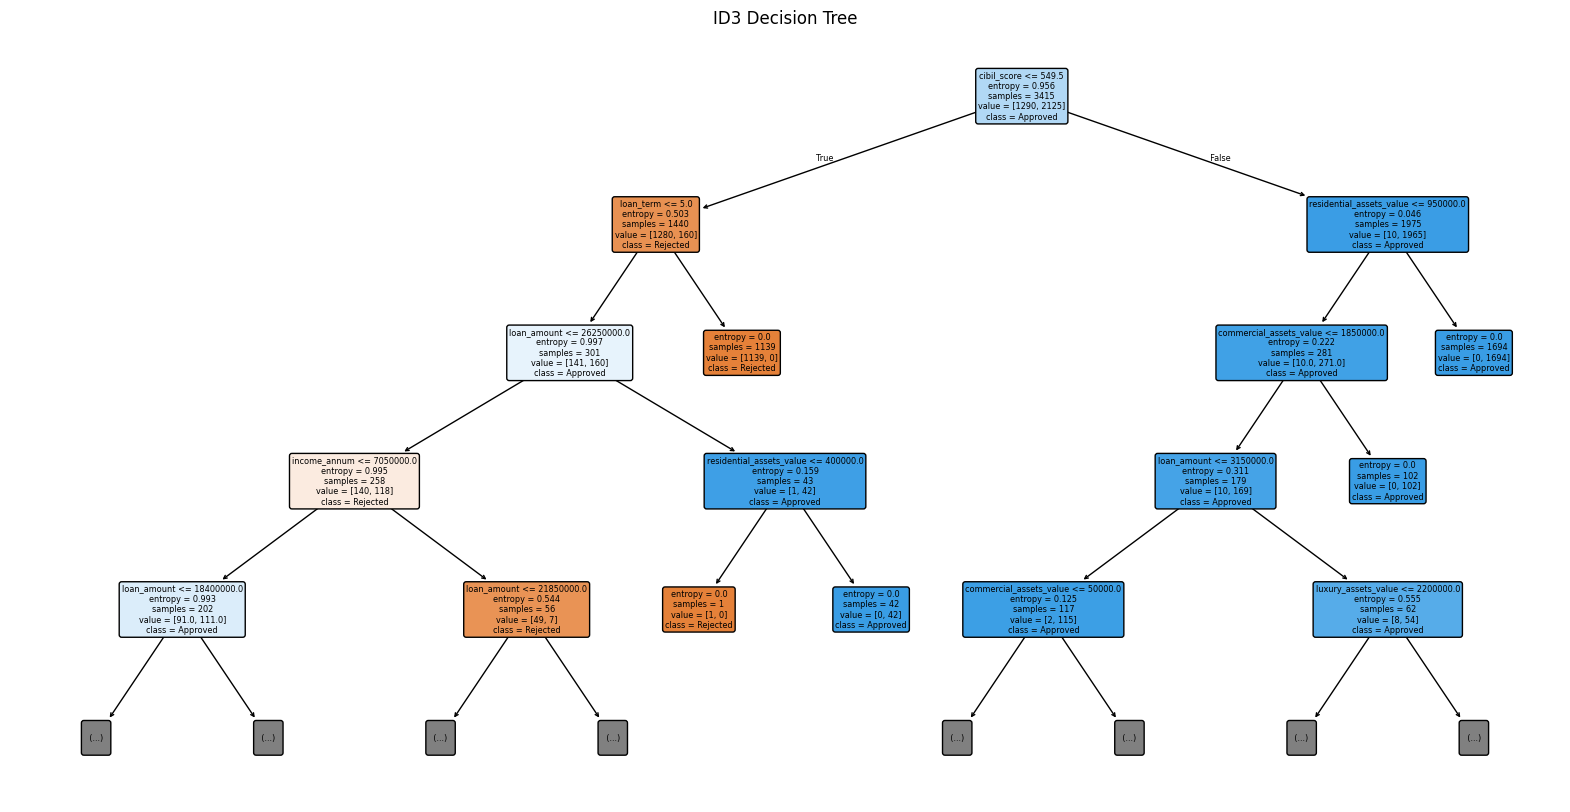

In [23]:
plt.figure(figsize=(20, 10))

plot_tree(
    id3_model,
    feature_names=X.columns,
    class_names=["Rejected", "Approved"],
    filled=True,
    rounded=True,
    max_depth=4
)

plt.title("ID3 Decision Tree")
plt.show()

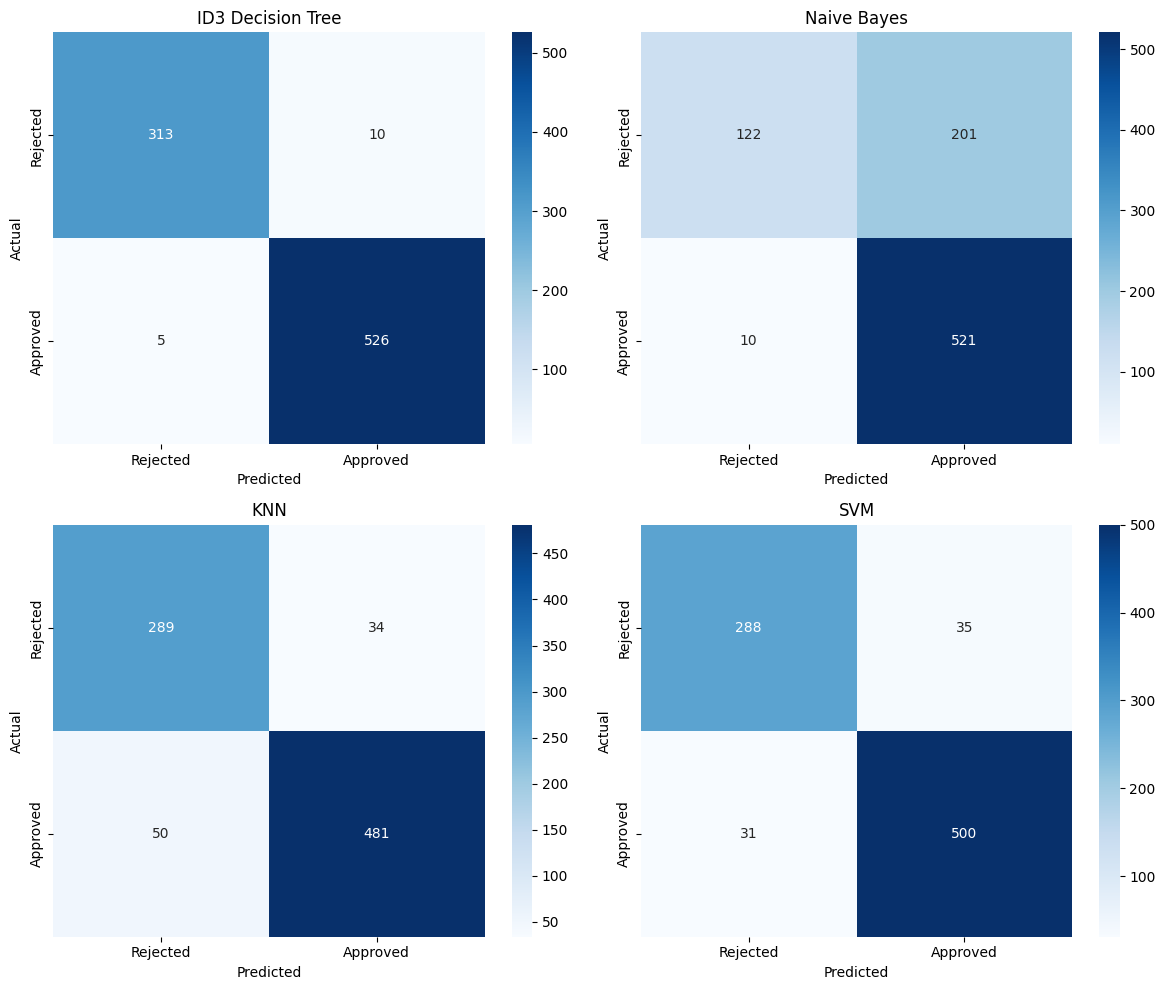

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (name, predictions) in zip(axes.ravel(), models_predictions.items()):
    cm = confusion_matrix(y_test, predictions, labels=[0, 1])

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Rejected", "Approved"],
        yticklabels=["Rejected", "Approved"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [25]:
for name, predictions in models_predictions.items():
    print("\n", name)
    print("----------------------")

    print(classification_report(
        y_test,
        predictions,
        labels=[0, 1],
        target_names=["Rejected", "Approved"],
        zero_division=0
    ))


 ID3 Decision Tree
----------------------
              precision    recall  f1-score   support

    Rejected       0.98      0.97      0.98       323
    Approved       0.98      0.99      0.99       531

    accuracy                           0.98       854
   macro avg       0.98      0.98      0.98       854
weighted avg       0.98      0.98      0.98       854


 Naive Bayes
----------------------
              precision    recall  f1-score   support

    Rejected       0.92      0.38      0.54       323
    Approved       0.72      0.98      0.83       531

    accuracy                           0.75       854
   macro avg       0.82      0.68      0.68       854
weighted avg       0.80      0.75      0.72       854


 KNN
----------------------
              precision    recall  f1-score   support

    Rejected       0.85      0.89      0.87       323
    Approved       0.93      0.91      0.92       531

    accuracy                           0.90       854
   macro avg       

In [26]:
best_model = results_df.loc[results_df["F1 Score"].idxmax()]

print("Best Algorithm:", best_model["Algorithm"])
print("Accuracy:", round(best_model["Accuracy"], 4))
print("Precision:", round(best_model["Precision"], 4))
print("Recall:", round(best_model["Recall"], 4))
print("F1 Score:", round(best_model["F1 Score"], 4))

Best Algorithm: ID3 Decision Tree
Accuracy: 0.9824
Precision: 0.9813
Recall: 0.9906
F1 Score: 0.9859
